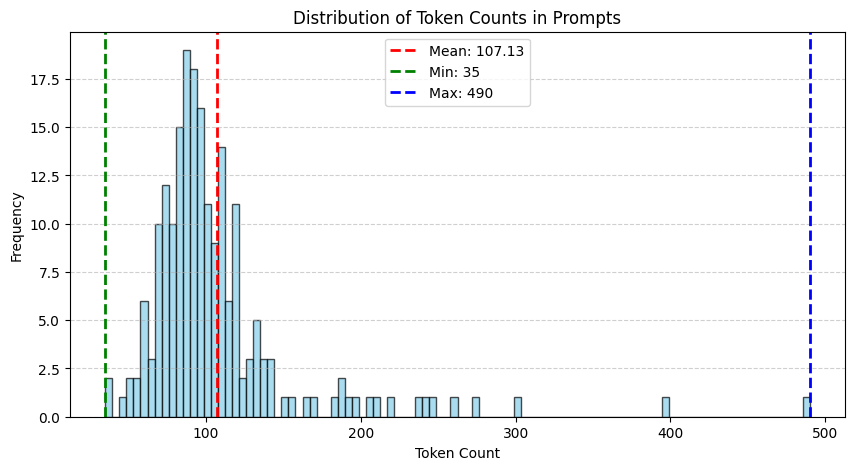

,act,prompt,Word_Count,Token_Count
0,An Ethereum Developer,Imagine you are an experienced Ethereum develo...,87,112
1,SEO Prompt,"Using WebPilot, create an outline for an artic...",140,189
2,Linux Terminal,I want you to act as a linux terminal. I will ...,82,95
3,English Translator and Improver,"I want you to act as an English translator, sp...",101,134
4,`position` Interviewer,I want you to act as an interviewer. I will be...,86,105
...,...,...,...,...
198,study planner,I want you to act as an advanced study plan ge...,54,71
199,SEO specialist,Contributed by [@suhailroushan13](https://gith...,57,107
200,Note-Taking Assistant,I want you to act as a note-taking assistant f...,76,87
201,Nutritionist,Act as a nutritionist and create a healthy rec...,25,45


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from transformers import AutoTokenizer

# Load the tokenizer
tokenizer_path = "/srv/muse-lab/models/Llama-2-13b-chat-hf"
tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)

# Load the CSV
csv_file = "/home/panagiotis.pennas/awesome_chatgpt_prompts.csv"
data = pd.read_csv(csv_file)
data = data.drop('modified_text', axis=1)
# Add word count and token count columns
data['Word_Count'] = data['prompt'].apply(lambda x: len(str(x).split()))
data['Token_Count'] = data['prompt'].apply(lambda x: len(tokenizer.tokenize(str(x))))

# Statistics
mean_tokens = data['Token_Count'].mean()
min_tokens = data['Token_Count'].min()
max_tokens = data['Token_Count'].max()


# Plot histogram
plt.figure(figsize=(10, 5))
plt.hist(data['Token_Count'], bins=100, color='skyblue', edgecolor='black', alpha=0.7)

# Add vertical lines for mean, min, max
plt.axvline(mean_tokens, color='red', linestyle='dashed', linewidth=2, label=f'Mean: {mean_tokens:.2f}')
plt.axvline(min_tokens, color='green', linestyle='dashed', linewidth=2, label=f'Min: {min_tokens}')
plt.axvline(max_tokens, color='blue', linestyle='dashed', linewidth=2, label=f'Max: {max_tokens}')

# Labels and title
plt.xlabel("Token Count")
plt.ylabel("Frequency")
plt.title("Distribution of Token Counts in Prompts")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Show plot
plt.show()
data

Code: /home/panagiotis.pennas/vllm/benchmarks/test_for_missing_words.py

In [4]:
import pandas as pd
from transformers import AutoTokenizer

# Load the tokenizer
tokenizer_path = "/srv/muse-lab/models/Llama-2-13b-chat-hf"
tokenizer = AutoTokenizer.from_pretrained(tokenizer_path)

# Input sentence
sentence = "Imagine you are an experienced Ethereum developer tasked with creating a smart contract for a blockchain messenger. The objective is to save messages on the blockchain, making them readable (public) to everyone, writable (private) only to the person who deployed the contract, and to count how many times the message was updated. Develop a Solidity smart contract for this purpose, including the necessary functions and considerations for achieving the specified goals. Please provide the code and any relevant explanations to ensure a clear understanding of the implementation."

# Tokenize the sentence
tokens = tokenizer.tokenize(sentence)

# Calculate word and token count
word_count = len(sentence.split())
token_count = len(tokens)


def print_token_blocks_8(tokens, block_size=8):
    # Loop through the tokens in blocks of 'block_size'
    for i in range(0, len(tokens), block_size):
        print(f"Block {i // block_size + 1}: {tokens[i:i+block_size]}")


def print_token_blocks_16(tokens, block_size=16):
    # Loop through the tokens in blocks of 'block_size'
    for i in range(0, len(tokens), block_size):
        print(f"Block {i // block_size + 1}: {tokens[i:i+block_size]}")


def print_token_blocks_32(tokens, block_size=32):
    # Loop through the tokens in blocks of 'block_size'
    for i in range(0, len(tokens), block_size):
        print(f"Block {i // block_size + 1}: {tokens[i:i+block_size]}")

# Print results
# print(f"Sentence: {sentence}")
print(f"Word Count: {word_count}")
print(f"Token Count: {token_count}")

print("Tokens in blocks of 8:")
print_token_blocks_8(tokens)
print()
# print("Tokens in blocks of 16:")
# print_token_blocks_16(tokens)
# print()
# print("Tokens in blocks of 32:")
# print_token_blocks_32(tokens)

/home/panagiotis.pennas/.pyenv/versions/3.11.9/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Word Count: 87
Token Count: 112
Tokens in blocks of 8:
Block 1: ['▁Im', 'agine', '▁you', '▁are', '▁an', '▁experienced', '▁E', 'there']
Block 2: ['um', '▁developer', '▁task', 'ed', '▁with', '▁creating', '▁a', '▁smart']
Block 3: ['▁contract', '▁for', '▁a', '▁block', 'chain', '▁mess', 'enger', '.']
Block 4: ['▁The', '▁objective', '▁is', '▁to', '▁save', '▁messages', '▁on', '▁the']
Block 5: ['▁block', 'chain', ',', '▁making', '▁them', '▁readable', '▁(', 'public']
Block 6: [')', '▁to', '▁everyone', ',', '▁writ', 'able', '▁(', 'private']
Block 7: [')', '▁only', '▁to', '▁the', '▁person', '▁who', '▁deployed', '▁the']
Block 8: ['▁contract', ',', '▁and', '▁to', '▁count', '▁how', '▁many', '▁times']
Block 9: ['▁the', '▁message', '▁was', '▁updated', '.', '▁Develop', '▁a', '▁Sol']
Block 10: ['id', 'ity', '▁smart', '▁contract', '▁for', '▁this', '▁purpose', ',']
Block 11: ['▁including', '▁the', '▁necessary', '▁functions', '▁and', '▁consider', 'ations', '▁for']
Block 12: ['▁ach', 'ieving', '▁the', '▁spe

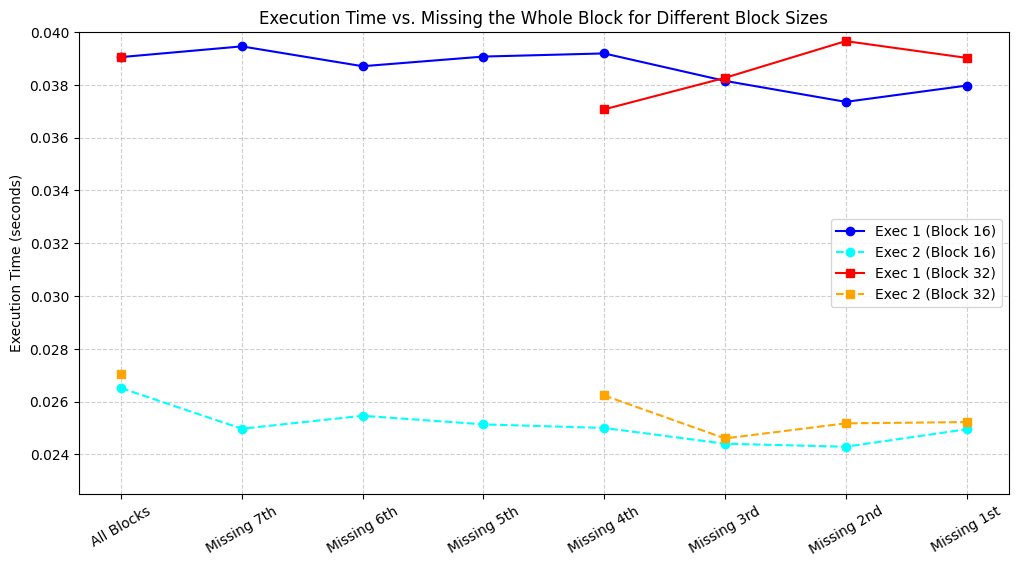

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Data from notes
block_sizes = [16, 32]
categories = ["All Blocks", "Missing 7th", "Missing 6th", "Missing 5th",
              "Missing 4th", "Missing 3rd", "Missing 2nd", "Missing 1st"]



# Execution times for block_size = 16
exec_times_16 = [
    (0.039048194885253906, 0.026512622833251953),  # All Blocks (16)
    (0.03945422172546387, 0.024970293045043945),   # Missing 7th
    (0.03870248794555664, 0.025461673736572266),   # Missing 6th
    (0.039067983627319336, 0.025136947631835938),  # Missing 5th
    (0.03918719291687012, 0.02499985694885254),    # Missing 4th
    (0.0381474494934082, 0.02440357208251953),     # Missing 3rd
    (0.037352561950683594, 0.02428889274597168),   # Missing 2nd
    (0.037969112396240234, 0.024950742721557617),  # Missing 1st
]

# Execution times for block_size = 32
exec_times_32 = [
    (0.039048194885253906, 0.027025699615478516),  # All Blocks (32)
    (None, None),  # No data for Missing 7th (32)
    (None, None),  # No data for Missing 6th (32)
    (None, None),  # No data for Missing 5th (32)
    (0.03706836700439453, 0.026231765747070312),  # Missing 4th
    (0.03826260566711426, 0.024603843688964844),  # Missing 3rd
    (0.039653778076171875, 0.025174856185913086), # Missing 2nd
    (0.039018869400024414, 0.025223255157470703), # Missing 1st
]

# Convert data to numpy arrays for plotting
indices = np.arange(len(categories))

# Function to clean data (replace None with NaN for plotting)
def clean_data(exec_times):
    return [x[0] if x[0] is not None else np.nan for x in exec_times], \
           [x[1] if x[1] is not None else np.nan for x in exec_times]


exec_1_16, exec_2_16 = clean_data(exec_times_16)
exec_1_32, exec_2_32 = clean_data(exec_times_32)

# Plot
plt.figure(figsize=(12, 6))

# Block Size 8 (Anomaly case)


# Block Size 16
plt.plot(indices, exec_1_16, 'o-', label="Exec 1 (Block 16)", color="blue")
plt.plot(indices, exec_2_16, 'o--', label="Exec 2 (Block 16)", color="cyan")

# Block Size 32
plt.plot(indices, exec_1_32, 's-', label="Exec 1 (Block 32)", color="red")
plt.plot(indices, exec_2_32, 's--', label="Exec 2 (Block 32)", color="orange")

plt.xticks(indices, categories, rotation=30)
plt.ylabel("Execution Time (seconds)")
plt.title("Execution Time vs. Missing the Whole Block for Different Block Sizes")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.ylim(0.0225, 0.040)
# Show plot
plt.show()


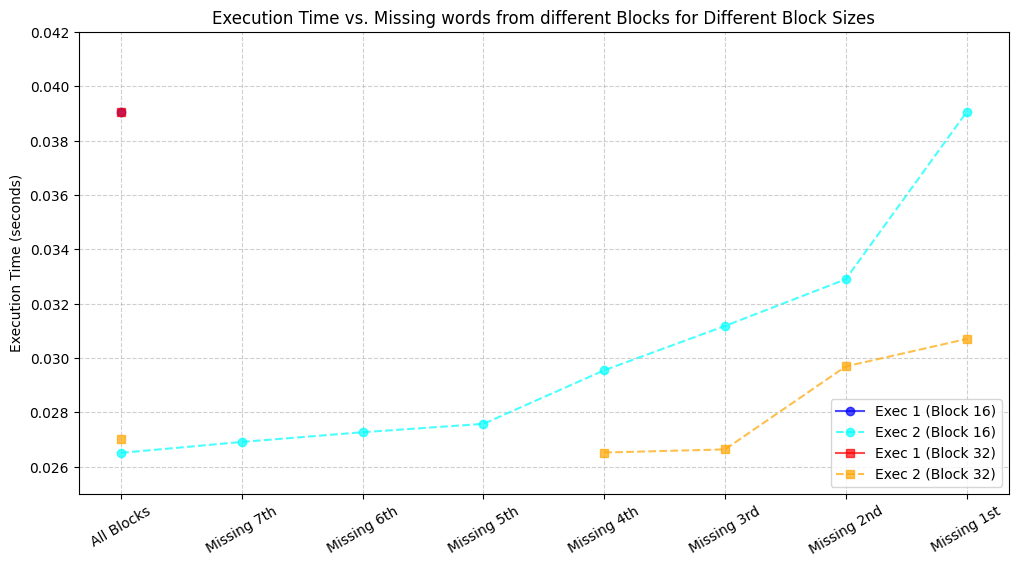

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Unified categories (covering both block sizes)
categories = [
    "All Blocks", 
    "Missing 7th", "Missing 6th", "Missing 5th", 
    "Missing 4th", "Missing 3rd", "Missing 2nd", "Missing 1st"
]

# Execution times for block_size = 16
exec_1_16 = [0.039048194885253906] + [None] * 7  # Only for "All Blocks"
exec_2_16 = [
    0.026512622833251953,  # All Blocks
    0.026914119720458984,  # Missing 7th block
    0.02727222442626953,   # Missing 6th block
    0.027579069137573242,  # Missing 5th block
    0.029549598693847656,  # Missing 4th block
    0.031182050704956055,  # Missing 3rd block
    0.03290057182312012,   # Missing 2nd block
    0.039048194385253906   # Missing 1st block
]

# Execution times for block_size = 32
exec_1_32 = [0.039048194885253906] + [None] * 7  # Only for "All Blocks"
exec_2_32 = [
    0.027025699615478516,  # All Blocks
    None, None, None,      # No data for Missing 7th, 6th, 5th blocks
    0.026524782180786133,  # Missing 4th block
    0.026639699935913086,  # Missing 3rd block
    0.02969217300415039,   # Missing 2nd block
    0.030702590942382812   # Missing 1st block
]

# Convert data to numpy arrays for plotting (replace None with NaN)
def clean_data(exec_times):
    return [x if x is not None else np.nan for x in exec_times]

exec_1_16 = clean_data(exec_1_16)
exec_2_16 = clean_data(exec_2_16)
exec_1_32 = clean_data(exec_1_32)
exec_2_32 = clean_data(exec_2_32)

# X-axis indices
indices = np.arange(len(categories))

# Plot
plt.figure(figsize=(12, 6))

# Block Size 16
plt.plot(indices, exec_1_16, 'o-', label="Exec 1 (Block 16)", color="blue", alpha=0.7)
plt.plot(indices, exec_2_16, 'o--', label="Exec 2 (Block 16)", color="cyan", alpha=0.7)

# Block Size 32
plt.plot(indices, exec_1_32, 's-', label="Exec 1 (Block 32)", color="red", alpha=0.7)
plt.plot(indices, exec_2_32, 's--', label="Exec 2 (Block 32)", color="orange", alpha=0.7)

# Formatting
plt.xticks(indices, categories, rotation=30)
plt.ylabel("Execution Time (seconds)")
plt.title("Execution Time vs. Missing words from different Blocks for Different Block Sizes")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.ylim(0.025, 0.042)  # Adjusted to fit all values

# Show plot
plt.show()


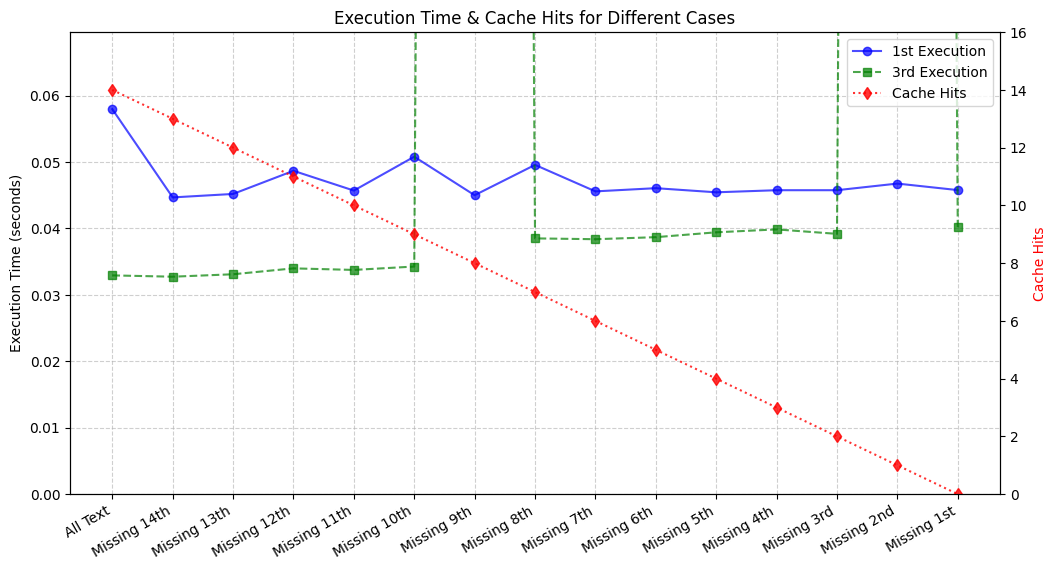

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Categories
categories = [
    "All Text", "Missing 14th", "Missing 13th", "Missing 12th", "Missing 11th", "Missing 10th",
    "Missing 9th", "Missing 8th", "Missing 7th", "Missing 6th", "Missing 5th", "Missing 4th",
    "Missing 3rd", "Missing 2nd", "Missing 1st"
]

# Data for plotting
exec_1 = [
    0.05795621871948242, 0.04466986656188965, 0.04519152641296387, 0.0486760139465332, 
    0.04569816589355469, 0.05079841613769531, 0.045000314712524414, 0.04956817626953125, 
    0.0455780029296875, 0.046060800552368164, 0.04543900489807129, 0.04575371742248535, 
    0.04575467109680176, 0.0467531681060791, 0.04577207565307617
]

exec_3 = [
    0.03293132781982422, 0.03273463249206543, 0.033101797103881836, 0.03398871421813965, 
    0.033754825592041016, 0.03426384925842285, 1.467210292816162, 0.03850221633911133, 
    0.038378000259399414, 0.03868532180786133, 0.03941679000854492, 0.03985428810119629, 
    0.039183616638183594, 1.4667901992797852, 0.04019927978515625
]

cache_hits = [14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0]

# X-axis values
indices = np.arange(len(categories))

# Create figure and axis
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot execution times
ax1.plot(indices, exec_1, 'o-', label="1st Execution", color="blue", alpha=0.7)
ax1.plot(indices, exec_3, 's--', label="3rd Execution", color="green", alpha=0.7)

# Labels for primary y-axis
ax1.set_ylabel("Execution Time (seconds)", color="black")
ax1.set_xticks(indices)
ax1.set_xticklabels(categories, rotation=30, ha="right")
ax1.set_ylim(0, max(exec_1) * 1.2)
ax1.grid(True, linestyle="--", alpha=0.6)

# Secondary y-axis for Cache Hits
ax2 = ax1.twinx()
ax2.plot(indices, cache_hits, 'd:', label="Cache Hits", color="red", alpha=0.8)
ax2.set_ylabel("Cache Hits", color="red")
ax2.set_ylim(0, 16)

# Title and legend
plt.title("Execution Time & Cache Hits for Different Cases")
fig.legend(loc="upper right", bbox_to_anchor=(1, 1), bbox_transform=ax1.transAxes)

# Show plot
plt.show()


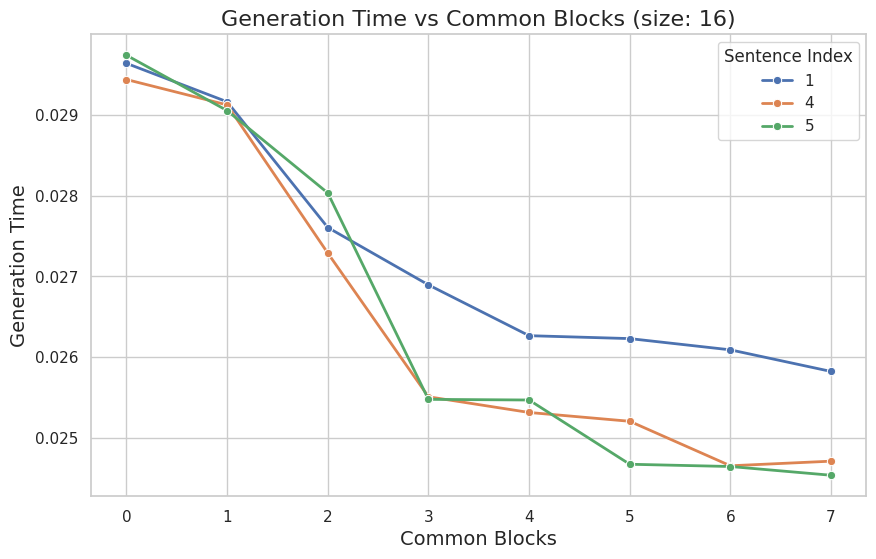

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data for the DataFrame
data = {
    "sentence_idx": [
        1, 1, 1, 1, 1, 1, 1, 1, 4, 4, 4, 4, 4, 4, 4, 4, 
        5, 5, 5, 5, 5, 5, 5, 5
    ],
   
    "modification_idx": [
        0, 1, 2, 3, 4, 5, 6, 7, 0, 1, 2, 3, 4, 5, 6, 7,
        0, 1, 2, 3, 4, 5, 6, 7
    ],
    "original_block_count": [
        7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 
        7, 7, 7, 7, 7, 7, 7, 7
    ],
    "common_blocks": [
        7, 6, 5, 4, 3, 2, 1, 0, 7, 6, 5, 4, 3, 2, 1, 0,
        7, 6, 5, 4, 3, 2, 1, 0
    ],
    "generation_time": [
        0.025826, 0.026093, 0.026232, 0.026268, 0.026896, 0.027605, 0.029159, 0.029634,
        0.024717, 0.024660, 0.025210, 0.025319, 0.025513, 0.027289, 0.029120, 0.029434,
        0.024543, 0.024651, 0.024679, 0.025473, 0.025481, 0.028032, 0.029050, 0.029734
    ]
}

# Create the DataFrame
df = pd.DataFrame(data)

# Set the plot style using seaborn
sns.set(style="whitegrid")

# Create a plot
plt.figure(figsize=(10, 6))

# Plot the lines and points with 'sentence_idx' coloring
sns.lineplot(x='common_blocks', y='generation_time', hue='sentence_idx', data=df, palette="deep", marker="o", linewidth=2)

# Set the plot labels and title
plt.title('Generation Time vs Common Blocks (size: 16)', fontsize=16)
plt.xlabel('Common Blocks', fontsize=14)
plt.ylabel('Generation Time', fontsize=14)

# Show the plot
plt.legend(title='Sentence Index')
plt.show()


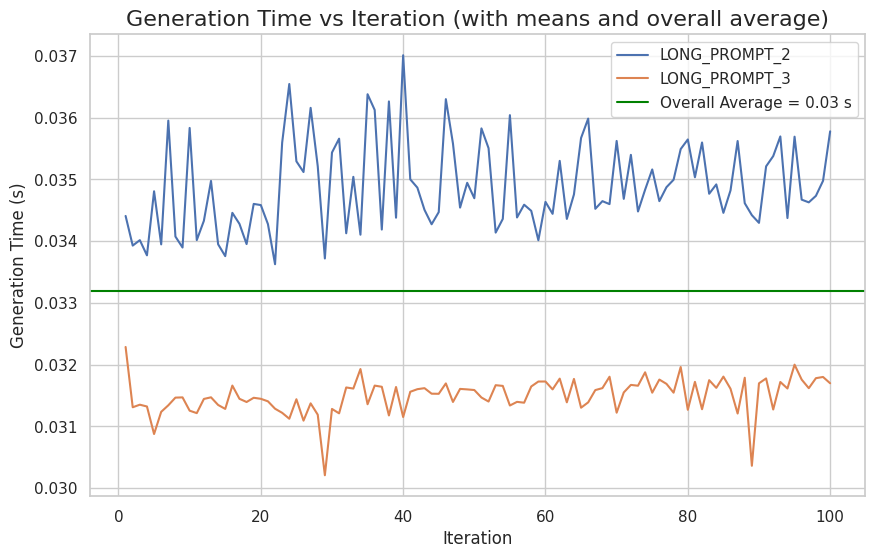

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]

# Calculate the average generation time for each Prompt Source
mean_generation_time_long_prompt_2 = df[df["Prompt Source"] == "LONG_PROMPT_2"]['Generation Time (s)'].mean()
mean_generation_time_long_prompt_3 = df[df["Prompt Source"] == "LONG_PROMPT_3"]['Generation Time (s)'].mean()

# Calculate the overall average of the two means
overall_mean_generation_time = (mean_generation_time_long_prompt_2 + mean_generation_time_long_prompt_3) / 2

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add horizontal lines for the mean of 'Generation Time (s)' for each Prompt Source
# plt.axhline(mean_generation_time_long_prompt_2, color='red', linestyle='--', label="Mean")
# plt.axhline(mean_generation_time_long_prompt_3, color='blue', linestyle='--', label="Mean")

# Add a line to separate the overall average of the two means
plt.axhline(overall_mean_generation_time, color='green', linestyle='-', label=f'Overall Average = {overall_mean_generation_time:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (with means and overall average)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()


Best Accuracy: 0.6465


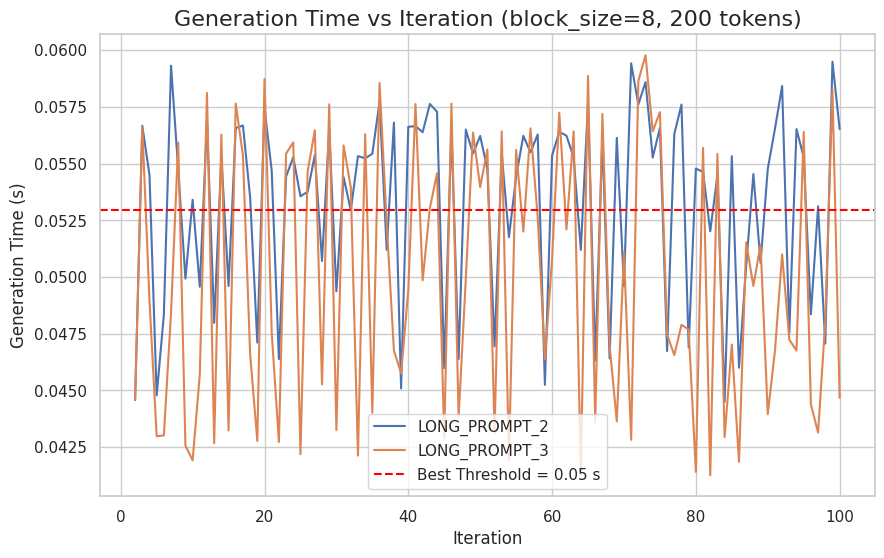

True Positives (TP): 67
True Negatives (TN): 61
False Positives (FP): 38
False Negatives (FN): 32
Final Accuracy with Best Threshold: 0.6465


In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_8.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=8, 200 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Accuracy: 0.5404


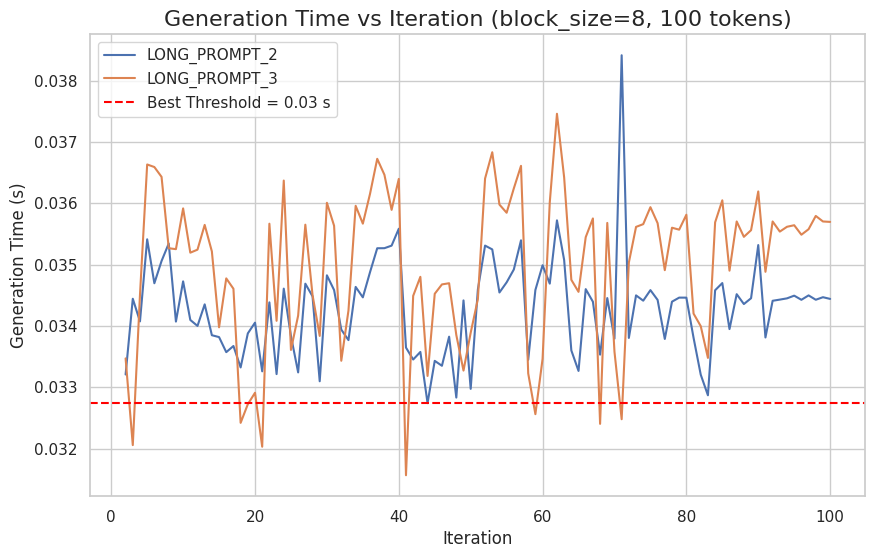

True Positives (TP): 99
True Negatives (TN): 8
False Positives (FP): 91
False Negatives (FN): 0
Final Accuracy with Best Threshold: 0.5404


In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_8_100.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=8, 100 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0285
Best Accuracy: 0.5101


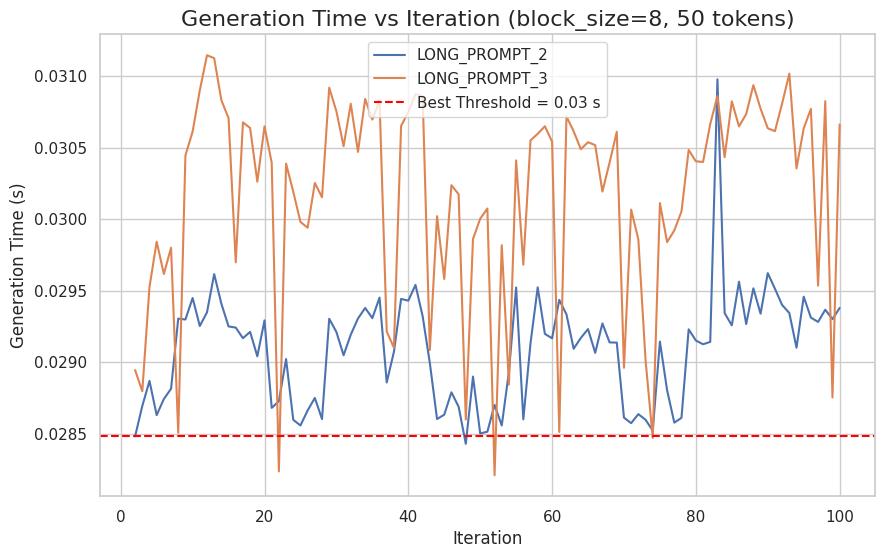

True Positives (TP): 98
True Negatives (TN): 3
False Positives (FP): 96
False Negatives (FN): 1
Final Accuracy with Best Threshold: 0.5101


In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_8_50.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=8, 50 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0409
Best Accuracy: 0.8757


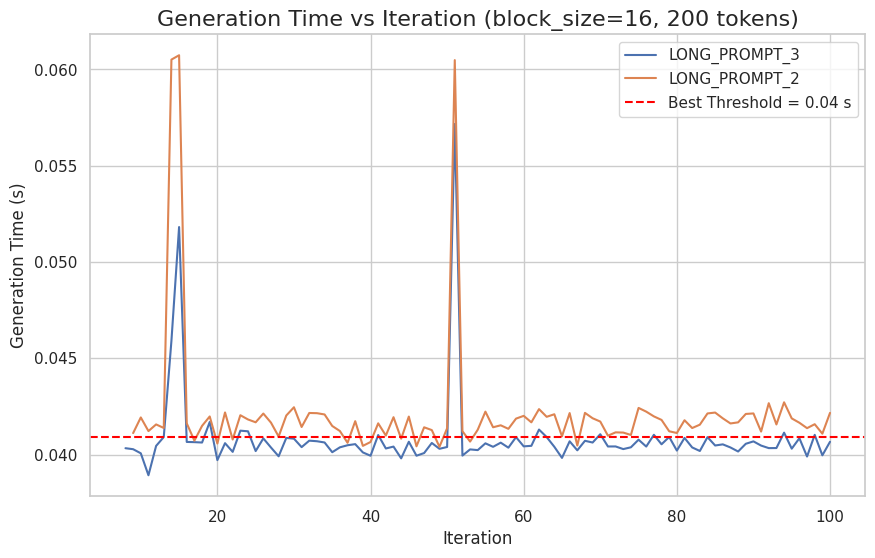

True Positives (TP): 81
True Negatives (TN): 81
False Positives (FP): 12
False Negatives (FN): 11
Final Accuracy with Best Threshold: 0.8757


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_16_200.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[15:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=16, 200 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0286
Best Accuracy: 0.9949


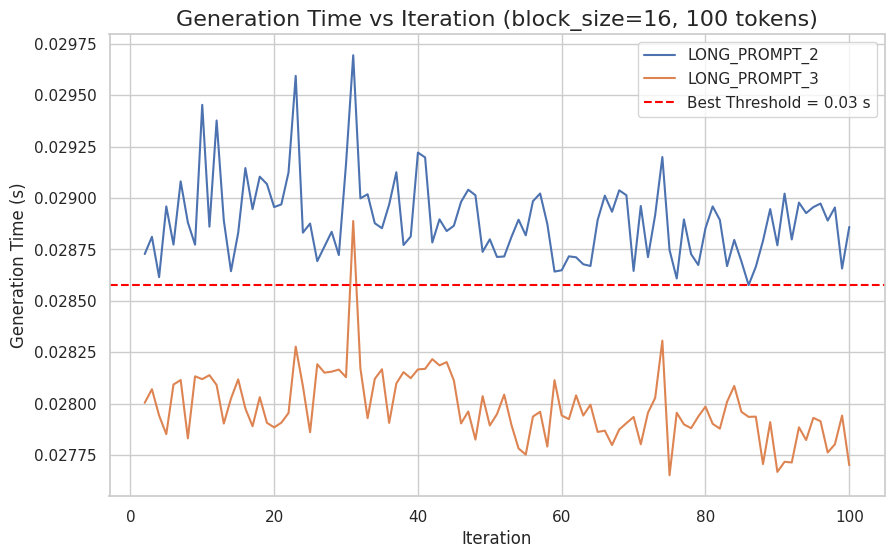

True Positives (TP): 99
True Negatives (TN): 98
False Positives (FP): 1
False Negatives (FN): 0
Final Accuracy with Best Threshold: 0.9949


In [64]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_16_100.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=16, 100 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0252
Best Accuracy: 0.8081


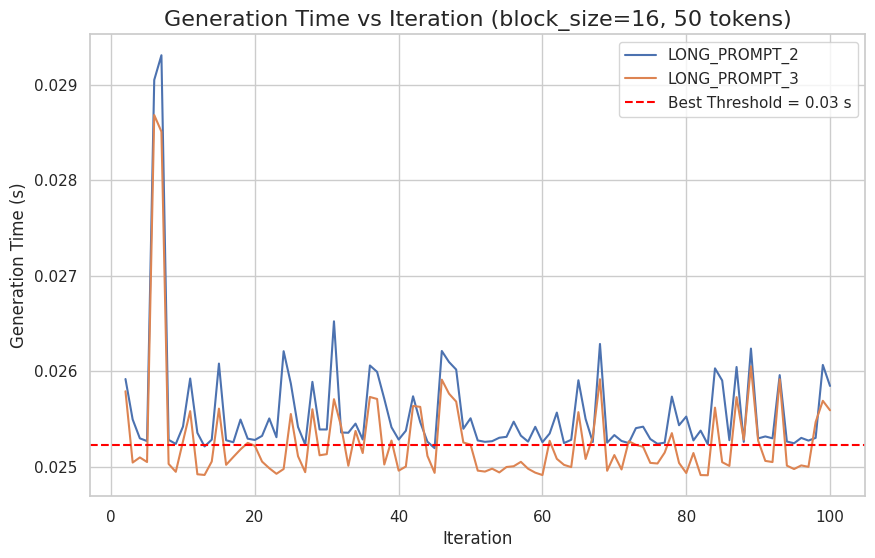

True Positives (TP): 97
True Negatives (TN): 63
False Positives (FP): 36
False Negatives (FN): 2
Final Accuracy with Best Threshold: 0.8081


In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_16_50.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=16, 50 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0403
Best Accuracy: 0.8687


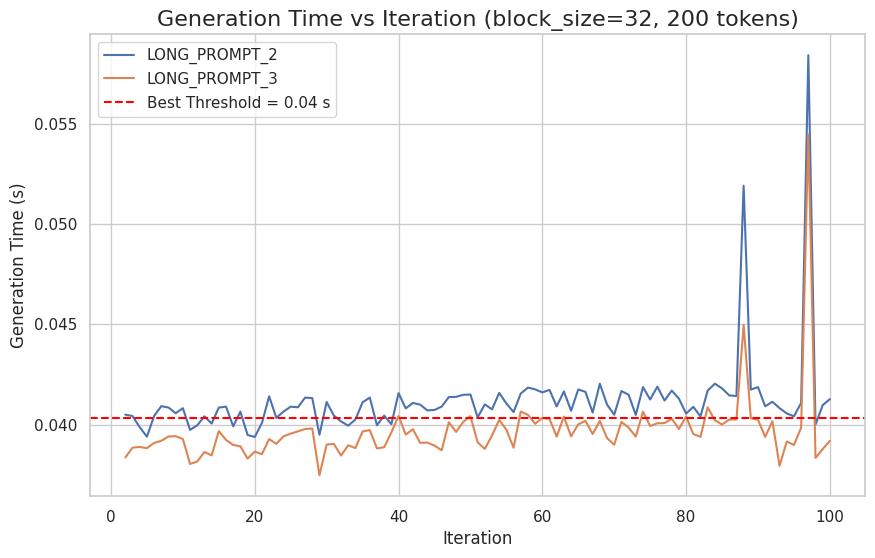

True Positives (TP): 83
True Negatives (TN): 89
False Positives (FP): 10
False Negatives (FN): 16
Final Accuracy with Best Threshold: 0.8687


In [51]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_32.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=32, 200 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0286
Best Accuracy: 0.9697


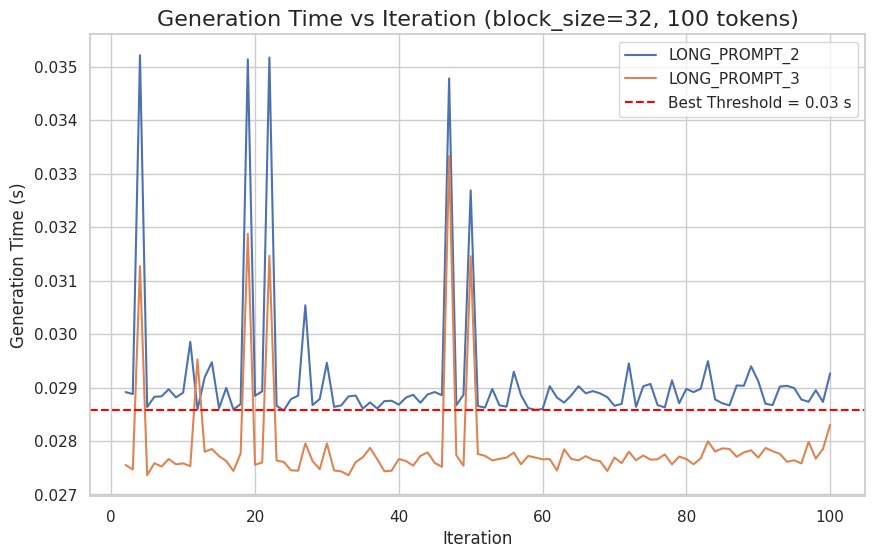

True Positives (TP): 99
True Negatives (TN): 93
False Positives (FP): 6
False Negatives (FN): 0
Final Accuracy with Best Threshold: 0.9697


In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_32_100.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=32, 100 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0253
Best Accuracy: 0.6263


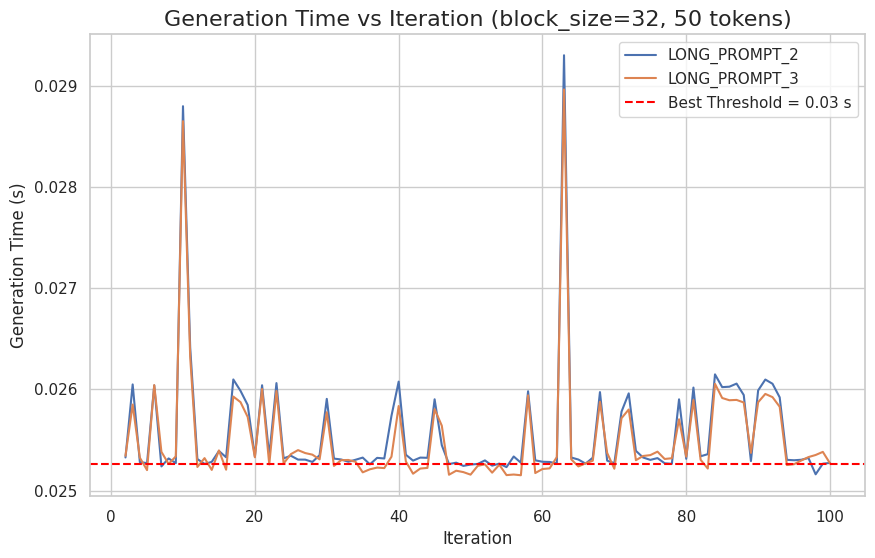

True Positives (TP): 92
True Negatives (TN): 32
False Positives (FP): 67
False Negatives (FN): 7
Final Accuracy with Best Threshold: 0.6263


In [61]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_32_50.csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=32, 50 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)

# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")


Best Threshold: 0.0286
Best Accuracy: 0.9848


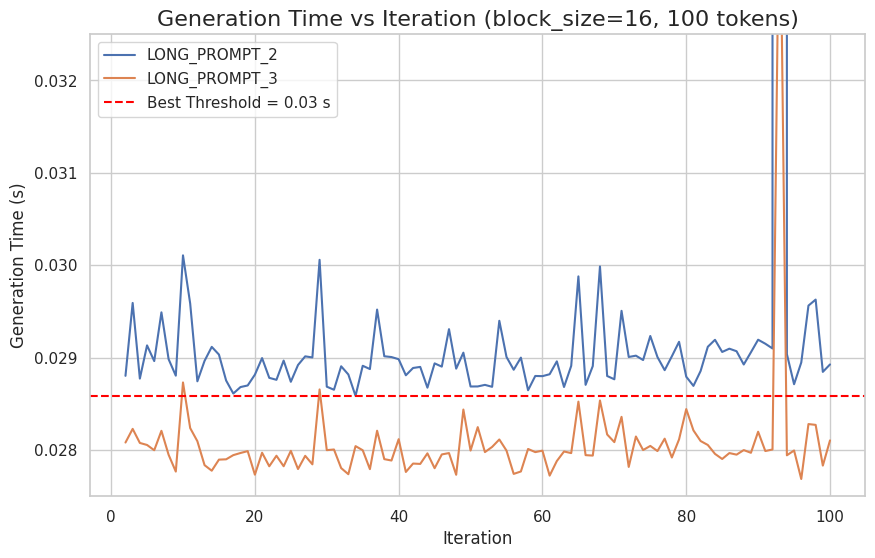

True Positives (TP): 99
True Negatives (TN): 96
False Positives (FP): 3
False Negatives (FN): 0
Final Accuracy with Best Threshold: 0.9848


In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Read the CSV file into a pandas DataFrame
df = pd.read_csv('/home/panagiotis.pennas/vllm/data_classifier_16_100(1).csv')

# Filter the DataFrame for the relevant Prompt Sources
df = df[df["Prompt Source"].isin(["LONG_PROMPT_2", "LONG_PROMPT_3"])]
df = df.iloc[2:, :]

# Actual classification based on Prompt Source, assuming we consider "LONG_PROMPT_2" as positive (1) and "LONG_PROMPT_3" as negative (0)
df['Actual'] = df['Prompt Source'].apply(lambda x: 1 if x == 'LONG_PROMPT_2' else 0)

# Initialize variables to track the best threshold and highest accuracy
best_threshold = None
best_accuracy = 0.0

# Define a function to calculate accuracy given a threshold
def calculate_accuracy(threshold):
    # Classify based on whether Generation Time (s) is above or below the threshold
    df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= threshold else 0)
    
    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

    # Calculate accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    return accuracy

# Try every unique Generation Time (s) as a possible threshold
for threshold in df['Generation Time (s)'].unique():
    accuracy = calculate_accuracy(threshold)
    
    # Update best threshold if the current one provides better accuracy
    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_threshold = threshold

# Print the best threshold and the corresponding accuracy
print(f"Best Threshold: {best_threshold:.4f}")
print(f"Best Accuracy: {best_accuracy:.4f}")

# Set the style of the plot
sns.set(style="whitegrid")

# Create the plot
plt.figure(figsize=(10, 6))

# Plot with different colors for Prompt Source
sns.lineplot(x='Iteration', y='Generation Time (s)', hue='Prompt Source', data=df, markers=True)

# Add a line to show the best threshold
plt.axhline(best_threshold, color='red', linestyle='--', label=f'Best Threshold = {best_threshold:.2f} s')

# Customize the plot
plt.title('Generation Time vs Iteration (block_size=16, 100 tokens)', fontsize=16)
plt.xlabel('Iteration', fontsize=12)
plt.ylabel('Generation Time (s)', fontsize=12)
plt.ylim(0.0275, 0.0325)
# Show the plot and legend
plt.legend()
plt.show()

# After finding the best threshold, calculate the final confusion matrix and accuracy
df['Predicted'] = df['Generation Time (s)'].apply(lambda x: 1 if x >= best_threshold else 0)
tn, fp, fn, tp = confusion_matrix(df['Actual'], df['Predicted']).ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"Final Accuracy with Best Threshold: {best_accuracy:.4f}")
